In [1]:
# import packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import calendar
import matplotlib.pyplot as plt
import pygris

In [2]:
# import cleaned fire dataset

project_fldr = Path.cwd().parents[1]

raw_fldr = project_fldr / 'data' / 'raw'
processed_fldr = project_fldr / 'data' / 'processed'

# read in CSV
fire_shp_25 = gpd.read_file(processed_fldr / "fire_shp_25/fire_shp_25.shp")
fire_shp_25.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 521 entries, 0 to 520
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   YEAR_       521 non-null    float64 
 1   STATE       521 non-null    str     
 2   AGENCY      521 non-null    str     
 3   UNIT_ID     521 non-null    str     
 4   FIRE_NAME   521 non-null    str     
 5   INC_NUM     521 non-null    str     
 6   IRWINID     469 non-null    str     
 7   ALARM_DATE  521 non-null    str     
 8   CONT_DATE   514 non-null    str     
 9   C_METHOD    521 non-null    int32   
 10  CAUSE       521 non-null    int32   
 11  OBJECTIVE   521 non-null    float64 
 12  GIS_ACRES   521 non-null    float64 
 13  COMPLEX_ID  17 non-null     str     
 14  COMPLEX_NA  17 non-null     str     
 15  COMMENTS    120 non-null    str     
 16  FIRE_NUM    0 non-null      object  
 17  Shape_Leng  521 non-null    float64 
 18  Shape_Area  521 non-null    float64 
 19  

In [3]:
fire_shp_25.head()

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,C_METHOD,...,COMPLEX_ID,COMPLEX_NA,COMMENTS,FIRE_NUM,Shape_Leng,Shape_Area,GlobalID,Alarm Mont,Alarm Mo_1,geometry
0,2025.0,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},2025/08/01 00:00:00+00,2025/10/14 00:00:00+00,3,...,NaN,NaN,NaN,None,257388.320379,5.326211e+08,{E87207FF-BD3D-4836-8A89-AD218A20B17E},8.0,Aug,"MULTIPOLYGON (((-35131.146 -302750.005, -35107..."
1,2025.0,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},2025/07/02 00:00:00+00,2025/07/26 00:00:00+00,7,...,NaN,NaN,NaN,None,191846.167384,3.269014e+08,{C59C71E2-F79F-440B-8C84-48058988F3CF},7.0,Jul,"POLYGON ((-4405.284 -313794.721, -4405.483 -31..."
2,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},2025/08/24 00:00:00+00,2025/10/23 00:00:00+00,3,...,NaN,NaN,NaN,None,234717.355087,2.428892e+08,{DDD0B278-7655-4F20-829D-FEEEF1DC935F},8.0,Aug,"MULTIPOLYGON (((89617.826 -122364.58, 89614.97..."
3,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},2025/09/02 00:00:00+00,2025/09/17 00:00:00+00,7,...,NaN,NaN,Park incident clipped out per BEU,None,90080.360959,1.034115e+08,{6817A72C-90CF-4CD4-8F26-2B9622F1F140},9.0,Sep,"POLYGON ((-31970.799 -229822.278, -31947.464 -..."
4,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025/01/07 00:00:00+00,2025/01/31 00:00:00+00,7,...,NaN,NaN,NaN,None,116028.197349,9.489426e+07,{73730F90-5D60-4850-98C2-2431C4284CD7},1.0,Jan,"MULTIPOLYGON (((136696.228 -441776.379, 136683..."


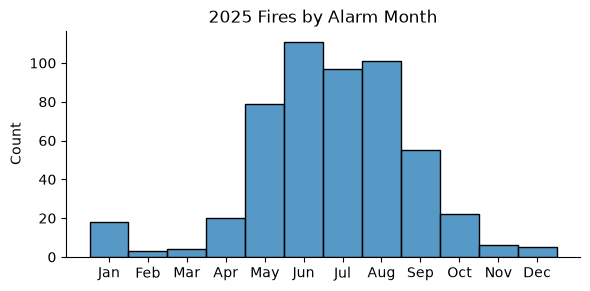

In [9]:
# Plot number of fires by month
fire_shp_25['Alarm Mo_1'] = pd.Categorical(
    values = fire_shp_25['Alarm Mo_1'],
    categories=calendar.month_abbr[1:]
)

g = sns.displot(
    data = fire_shp_25,
    x = 'Alarm Mo_1',   
    height=3,
    aspect=2
)

g.set(
    title = "2025 Fires by Alarm Month",
    xlabel="",
    ylabel="Count"
);

As expected we see a lot of fire around fall. Over 80 fire incidents happening each month in months May to Aug. Reletively less fire in months Apr, Sep, Oct. Very little in months Feb, Mar, Nov, Dec. 

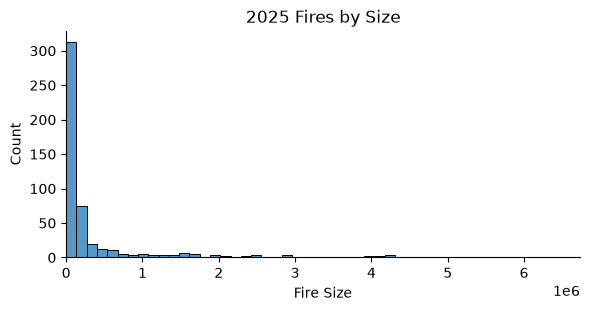

In [27]:
#plot fire size (<=90th percentile)
upper_limit = fire_shp_25['Shape_Area'].quantile(0.95)

g = sns.displot(
    data=fire_shp_25[fire_shp_25['Shape_Area'] <= upper_limit],
    x = 'Shape_Area', 
    bins=50,  
    height=3,
    aspect=2
)

g.set(
    title="2025 Fires by Size",
    xlabel="Fire Size",
    ylabel="Count",
    xlim=(0, upper_limit),
    ylim=(0, None)
)

The distribution is heavily right-skewed, indicating that most fires are relatively small, while a small number of fires are substantially larger. To better visualize the distribution of typical fire sizes, we zoomed in on fires below the 90th percentile.

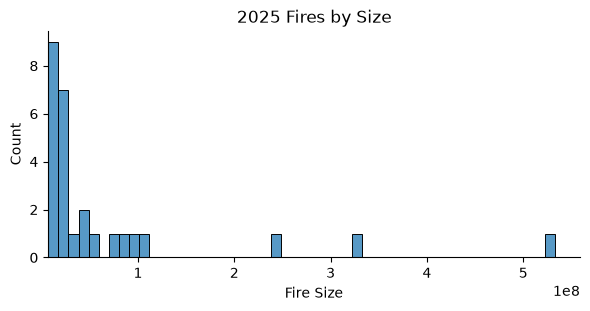

In [26]:
#plot fire size (large ones)
lower_limit = fire_shp_25['Shape_Area'].quantile(0.95)

g = sns.displot(
    data=fire_shp_25[fire_shp_25['Shape_Area'] >= lower_limit],
    x = 'Shape_Area', 
    bins=50,  
    height=3,
    aspect=2
)

g.set(
    title="2025 Fires by Size",
    xlabel="Fire Size",
    ylabel="Count",
    xlim=(lower_limit, None),
    ylim=(0, None)
)

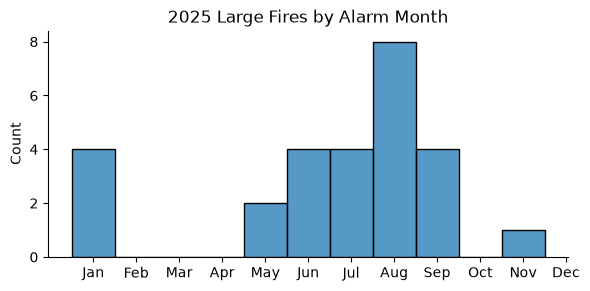

In [28]:
#plot large fires by alarm month

large_fires = fire_shp_25[fire_shp_25['Shape_Area'] >= upper_limit]

g = sns.displot(
    data = large_fires,
    x = 'Alarm Mo_1',   
    height=3,
    aspect=2
)

g.set(
    title = "2025 Large Fires by Alarm Month",
    xlabel="",
    ylabel="Count"
);

Large fires occur more frequently in the fall, although some also occur in January, with the same number of large fires as in June, July, and September. The occurrence of large fires in January is particularly interesting and may warrant further investigation into the factors contributing to these winter fire events.